In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

Loading Data

In [5]:
df = pd.read_csv('European_Bank.csv')

In [6]:
df

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2025,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,2025,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,2025,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,2025,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


Data Understanding

In [7]:
df.shape

(10000, 14)

In [8]:
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [10]:
df.isnull().sum()

Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [11]:
df.columns

Index(['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender',
       'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df['Year'].value_counts().sort_index()

Year
2025    10000
Name: count, dtype: int64

In [14]:
df['Year'].min(), df['Year'].max()

(np.int64(2025), np.int64(2025))

In [15]:
df.groupby('Year')['Exited'].mean()*100

Year
2025    20.37
Name: Exited, dtype: float64

In [16]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [17]:
df.describe()

,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [18]:
df['Exited'].value_counts(normalize=True) * 100

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

In [19]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [20]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [21]:
df['HasCrCard'].value_counts()

HasCrCard
1    7055
0    2945
Name: count, dtype: int64

In [22]:
df['IsActiveMember'].value_counts()

IsActiveMember
1    5151
0    4849
Name: count, dtype: int64

In [23]:
df['NumOfProducts'].value_counts()

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

In [24]:
df['Tenure'].value_counts().sort_index()

Tenure
0      413
1     1035
2     1048
3     1009
4      989
5     1012
6      967
7     1028
8     1025
9      984
10     490
Name: count, dtype: int64

In [25]:
df['CreditScore'].describe()

count    10000.000000
mean       650.528800
std         96.653299
min        350.000000
25%        584.000000
50%        652.000000
75%        718.000000
max        850.000000
Name: CreditScore, dtype: float64

# Data Cleaning and Preprocessing

In [26]:
df_cleaned = df.copy()

In [27]:
df_cleaned = df_cleaned.drop(columns=['CustomerId', 'Surname'])

In [28]:
df_cleaned.shape

(10000, 12)

In [29]:
df_cleaned['Year'].nunique()

1

In [30]:
df_cleaned.columns

Index(['Year', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited'],
      dtype='object')

In [31]:
df_cleaned.dtypes

Year                 int64
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [32]:
df_cleaned = pd.get_dummies(
    df_cleaned, columns= ['Geography', 'Gender'],drop_first=True
)

In [33]:
df_cleaned.columns

Index(['Year', 'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
       'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited',
       'Geography_Germany', 'Geography_Spain', 'Gender_Male'],
      dtype='object')

# EDA

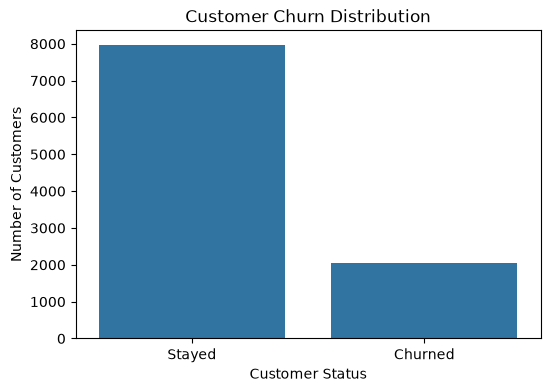

In [34]:
plt.figure(figsize=(6,4))

sns.countplot(data=df_cleaned, x='Exited')

plt.xticks([0,1],['Stayed', 'Churned'])
plt.title('Customer Churn Distribution')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')

plt.show()

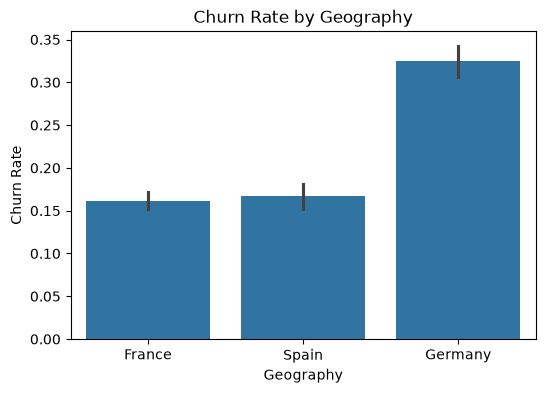

In [35]:
plt.figure(figsize=(6,4))

sns.barplot(data=df, x= 'Geography', y= 'Exited')

plt.title('Churn Rate by Geography')
plt.xlabel('Geography')
plt.ylabel('Churn Rate')

plt.show()

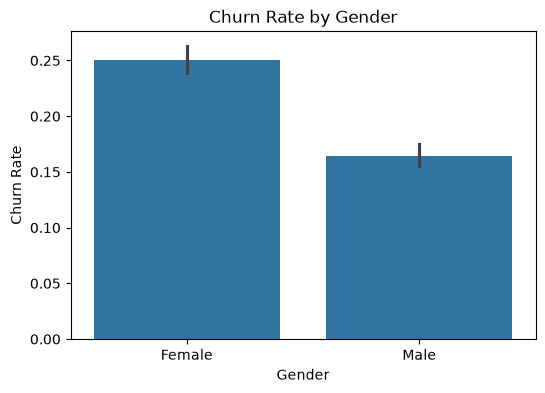

In [36]:
plt.figure(figsize=(6,4))

sns.barplot(data=df, x= 'Gender', y= 'Exited')

plt.title('Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate')
plt.show()

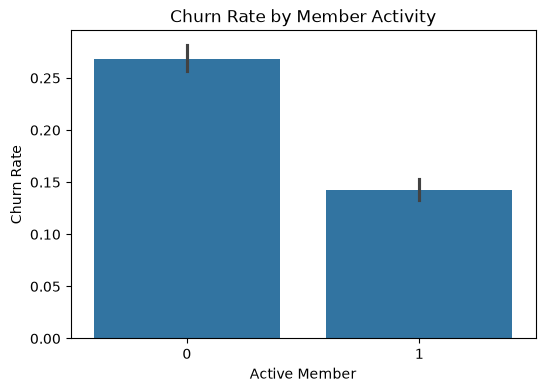

In [37]:
plt.figure(figsize=(6,4))

sns.barplot(data= df_cleaned, x= 'IsActiveMember', y= 'Exited')

plt.title('Churn Rate by Member Activity')
plt.xlabel('Active Member')
plt.ylabel('Churn Rate')

plt.show()

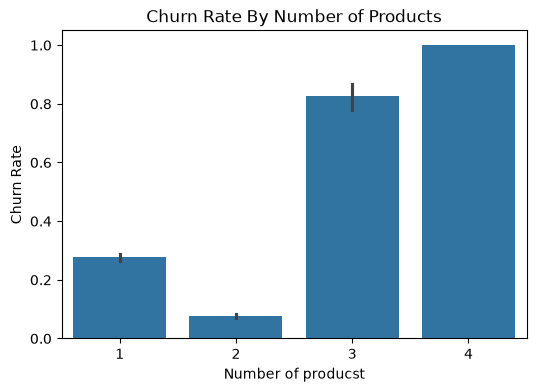

In [38]:
plt.figure(figsize=(6,4))

sns.barplot(data=df_cleaned, x='NumOfProducts', y= 'Exited')

plt.title('Churn Rate By Number of Products')
plt.xlabel('Number of producst')
plt.ylabel('Churn Rate')

plt.show()

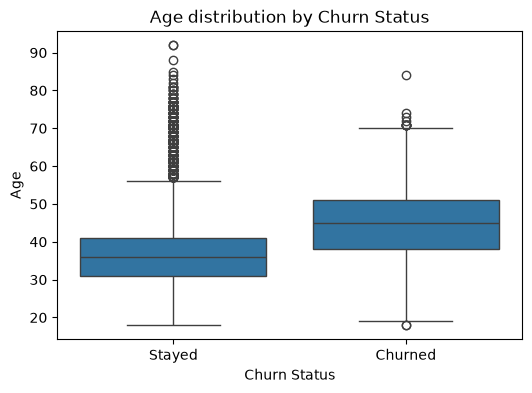

In [39]:
plt.figure(figsize=(6,4))

sns.boxplot(data=df_cleaned, x= 'Exited', y= 'Age')

plt.xticks([0,1], ['Stayed', 'Churned'])

plt.title('Age distribution by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Age')

plt.show()

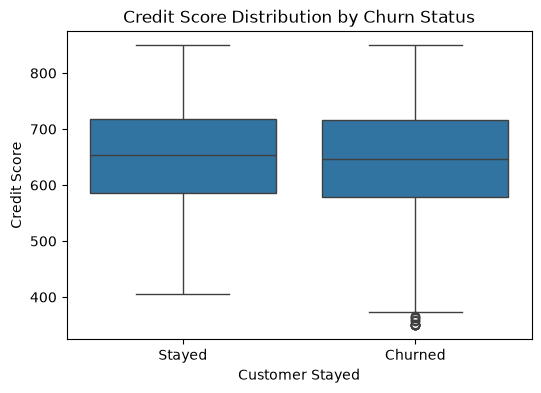

In [40]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df_cleaned, x= 'Exited', y= 'CreditScore')

plt.xticks([0,1], ['Stayed', 'Churned'])

plt.title('Credit Score Distribution by Churn Status')
plt.xlabel('Customer Stayed')
plt.ylabel('Credit Score')

plt.show()

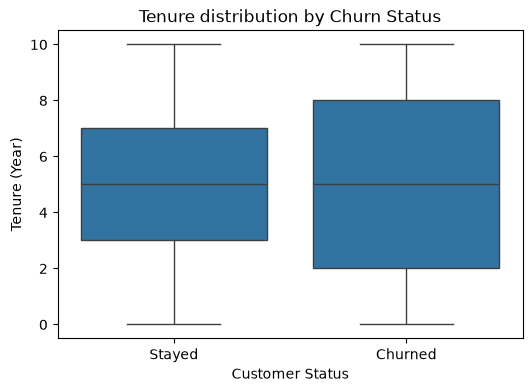

In [41]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df_cleaned, x= 'Exited', y= 'Tenure')

plt.xticks([0,1], ['Stayed', 'Churned'])

plt.title('Tenure distribution by Churn Status')
plt.xlabel('Customer Status')
plt.ylabel('Tenure (Year)')

plt.show()

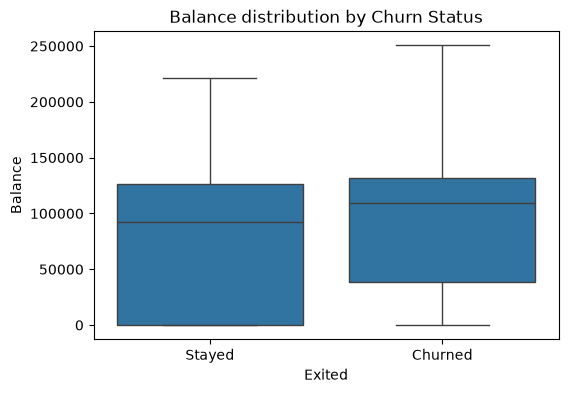

In [42]:
plt.figure(figsize=(6,4))
sns.boxplot(data= df_cleaned, x= 'Exited', y= 'Balance')
plt.xticks([0,1], ['Stayed', 'Churned'])

plt.title('Balance distribution by Churn Status')
plt.ylabel('Balance')

plt.show()

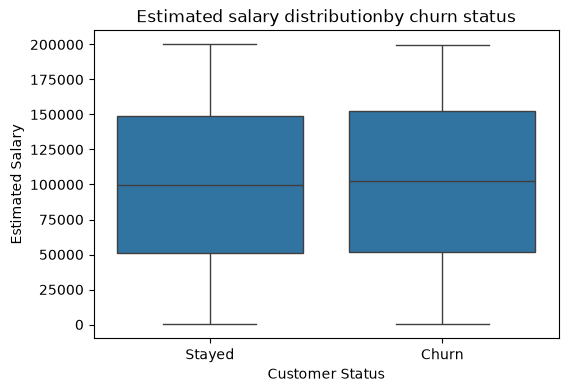

In [43]:
plt.figure(figsize=(6,4))

sns.boxplot(data= df_cleaned, x= 'Exited', y= 'EstimatedSalary')
plt.xticks([0,1], ['Stayed', 'Churn'])

plt.title('Estimated salary distributionby churn status')
plt.xlabel('Customer Status')
plt.ylabel('Estimated Salary')

plt.show()

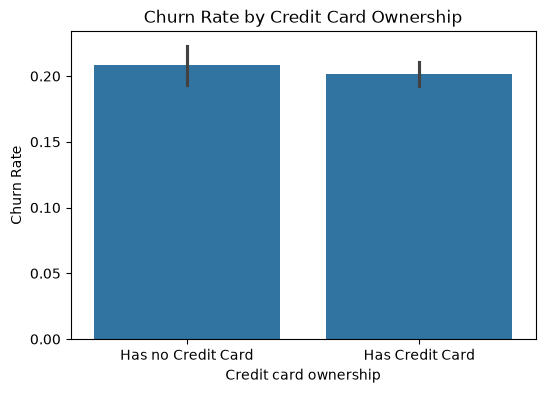

In [44]:
plt.figure(figsize=(6,4))

sns.barplot(data= df_cleaned, x= 'HasCrCard', y= 'Exited')
plt.xticks([0,1], ['Has no Credit Card', 'Has Credit Card'])

plt.title('Churn Rate by Credit Card Ownership')
plt.xlabel('Credit card ownership')
plt.ylabel('Churn Rate')

plt.show()

In [45]:
df_cleaned.corr(numeric_only=True)['Exited'].sort_values(ascending=False)

Exited               1.000000
Age                  0.285323
Geography_Germany    0.173488
Balance              0.118533
EstimatedSalary      0.012097
HasCrCard           -0.007138
Tenure              -0.014001
CreditScore         -0.027094
NumOfProducts       -0.047820
Geography_Spain     -0.052667
Gender_Male         -0.106512
IsActiveMember      -0.156128
Year                      NaN
Name: Exited, dtype: float64

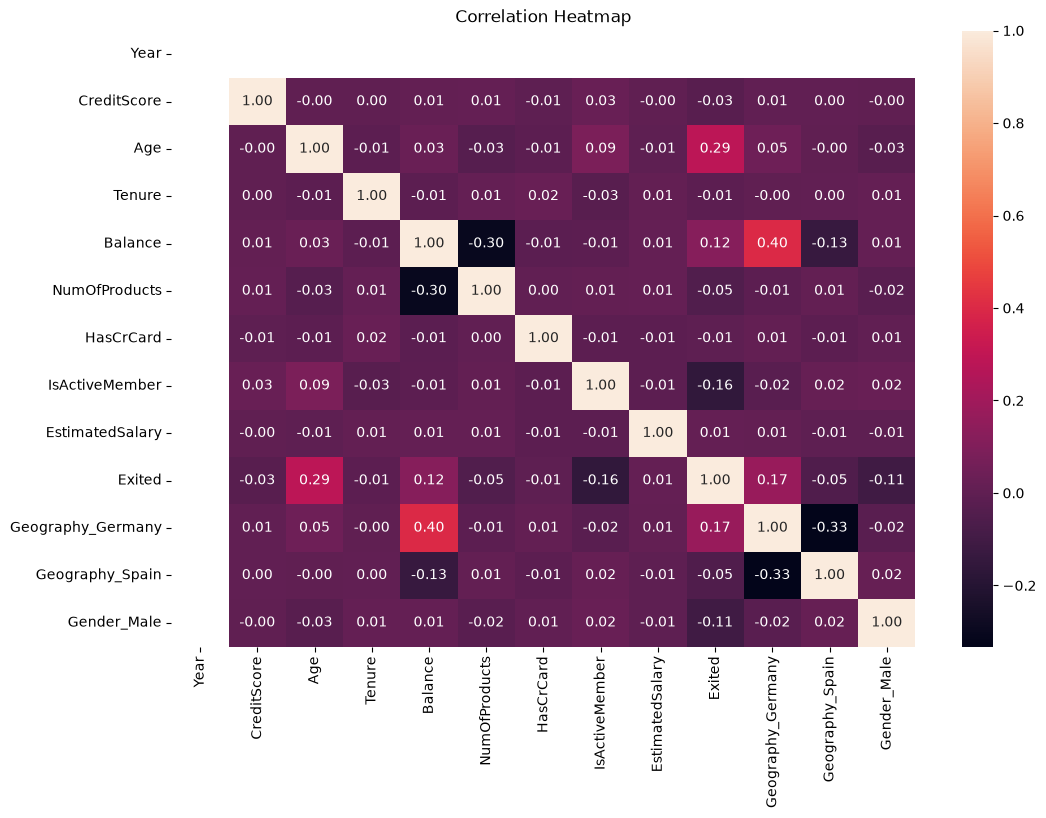

In [46]:
plt.figure(figsize=(12, 8))

corr = df_cleaned.corr(numeric_only=True)

sns.heatmap(corr,annot=True,fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

# Feature Engineering

In [47]:
df_cleaned['BalanceSalaryRatio'] = (
    df_cleaned['Balance'] / df_cleaned['EstimatedSalary']
)

In [48]:
df_cleaned[["Balance", "EstimatedSalary", "BalanceSalaryRatio"]].head()

,Balance,EstimatedSalary,BalanceSalaryRatio
0,0.00,101348.88,0.000000
1,83807.86,112542.58,0.744677
2,159660.80,113931.57,1.401375
3,0.00,93826.63,0.000000
4,125510.82,79084.10,1.587055


In [49]:
df_cleaned['ProductDensity'] = (
    df_cleaned['NumOfProducts'] / (df_cleaned['Tenure'] + 1)
)

In [50]:
df_cleaned[["NumOfProducts", "Tenure", "ProductDensity"]].head()

,NumOfProducts,Tenure,ProductDensity
0,1,2,0.333333
1,1,1,0.500000
2,3,8,0.333333
3,2,1,1.000000
4,1,2,0.333333


In [51]:
df_cleaned['EngagementProduct'] = (
    df_cleaned['IsActiveMember'] * df_cleaned['NumOfProducts']
)

In [52]:
df_cleaned[
    ["IsActiveMember", "NumOfProducts", "EngagementProduct"]
].head()

,IsActiveMember,NumOfProducts,EngagementProduct
0,1,1,1
1,1,1,1
2,0,3,0
3,0,2,0
4,1,1,1


In [53]:
df_cleaned['AgeTenureInteraction'] = (
    df_cleaned['Age'] * df_cleaned['Tenure']
)

In [54]:
df_cleaned[
    ["Age", "Tenure", "AgeTenureInteraction"]
].head()

,Age,Tenure,AgeTenureInteraction
0,42,2,84
1,41,1,41
2,42,8,336
3,39,1,39
4,43,2,86


In [55]:
df_cleaned.columns

Index(['Year', 'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
       'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited',
       'Geography_Germany', 'Geography_Spain', 'Gender_Male',
       'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct',
       'AgeTenureInteraction'],
      dtype='object')

In [56]:
df_cleaned.columns

Index(['Year', 'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
       'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited',
       'Geography_Germany', 'Geography_Spain', 'Gender_Male',
       'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct',
       'AgeTenureInteraction'],
      dtype='object')

In [57]:
X = df_cleaned.drop(columns=['Exited'])
Y = df_cleaned['Exited']

In [58]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,Y,
    test_size=0.2, stratify=Y, random_state=42
)

In [59]:
print("Training:")
print(Y_train.value_counts(normalize=True) * 100)

print("\nTesting:")
print(Y_test.value_counts(normalize=True) * 100)

Training:
Exited
0    79.625
1    20.375
Name: proportion, dtype: float64

Testing:
Exited
0    79.65
1    20.35
Name: proportion, dtype: float64


In [60]:
from sklearn.preprocessing import StandardScaler

In [61]:
numerical_features = [
    'Year',
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'EstimatedSalary',
    'BalanceSalaryRatio',
    'ProductDensity',
    'EngagementProduct',
    'AgeTenureInteraction'
]

In [62]:
scaler = StandardScaler()

In [63]:
scaler.fit(X_train[numerical_features])

StandardScaler()

In [64]:
X_train_scaled = X_train.copy()
X_train_scaled[numerical_features] = scaler.transform(
    X_train[numerical_features]
)

In [65]:
X_test_scaled = X_test.copy()

X_test_scaled[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

In [66]:
X_train_scaled[numerical_features].head()

,Year,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,BalanceSalaryRatio,ProductDensity,EngagementProduct,AgeTenureInteraction
2151,0.0,1.058568,1.715086,0.684723,-1.226059,-0.910256,1.042084,-0.034927,-0.719828,-0.908608,1.580589
8392,0.0,0.913626,-0.659935,-0.696202,0.413288,-0.910256,-0.623556,-0.021722,-0.346241,-0.908608,-0.770341
5006,0.0,1.079274,-0.184931,-1.731895,0.601687,0.808830,0.308128,-0.026903,4.883987,1.390574,-1.515190
4117,0.0,-0.929207,-0.184931,-0.005739,-1.226059,0.808830,-0.290199,-0.034927,-0.097182,-0.908608,-0.079804
7182,0.0,0.427035,0.955079,0.339492,0.548318,0.808830,0.135042,-0.026418,-0.239501,1.390574,0.765910


In [67]:
from sklearn.linear_model import LogisticRegression

In [68]:
log_model = LogisticRegression(
    random_state= 42, max_iter= 1000
)

In [69]:
log_model.fit(X_train_scaled, Y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [70]:
Y_pred = log_model.predict(X_test_scaled)

In [71]:
from sklearn.metrics import accuracy_score

In [72]:
accuracy = accuracy_score(Y_test, Y_pred)
print(f'Accuracy : {accuracy:.4f}')

Accuracy : 0.8070


In [73]:
from sklearn.metrics import precision_score

In [74]:
precision = precision_score(Y_test, Y_pred)

print(f"Precision: {precision:.4f}")

Precision: 0.5778


In [75]:
from sklearn.metrics import recall_score

recall = recall_score(Y_test, Y_pred)

print(f"Recall: {recall:.4f}")

Recall: 0.1916


In [76]:
from sklearn.metrics import f1_score

f1 = f1_score(Y_test, Y_pred)

print(f"F1-Score: {f1:.4f}")

F1-Score: 0.2878


In [77]:
from sklearn.metrics import roc_auc_score

Y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(Y_test, Y_prob)

print(f"ROC-AUC: {roc_auc:.4f}")

ROC-AUC: 0.7736


In [78]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, Y_pred)

print(cm)

[[1536   57]
 [ 329   78]]


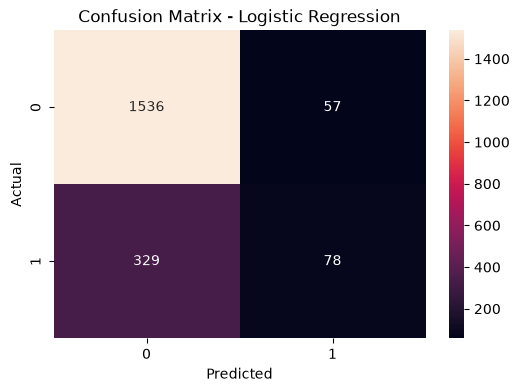

In [79]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [80]:
from sklearn.tree import DecisionTreeClassifier

In [81]:
dt_model = DecisionTreeClassifier(random_state=42)

In [82]:
dt_model.fit(X_train, Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [83]:
dt_pred = dt_model.predict(X_test)

In [84]:

dt_accuracy = accuracy_score(Y_test, dt_pred)

print(f"Decision Tree Accuracy: {dt_accuracy:.4f}")

Decision Tree Accuracy: 0.7830


In [85]:
dt_precision = precision_score(Y_test, dt_pred)

print(f"Decision Tree Precision: {dt_precision:.4f}")

Decision Tree Precision: 0.4682


In [86]:
dt_recall = recall_score(Y_test, dt_pred)

print(f"Decision Tree Recall: {dt_recall:.4f}")

Decision Tree Recall: 0.4889


In [87]:
dt_f1 = f1_score(Y_test, dt_pred)

print(f"Decision Tree F1-Score: {dt_f1:.4f}")

Decision Tree F1-Score: 0.4784


In [88]:
dt_prob = dt_model.predict_proba(X_test)[:, 1]

dt_roc_auc = roc_auc_score(Y_test, dt_prob)

print(f"Decision Tree ROC-AUC: {dt_roc_auc:.4f}")

Decision Tree ROC-AUC: 0.6735


In [89]:
from sklearn.ensemble import RandomForestClassifier

In [90]:
rf_model = RandomForestClassifier(random_state=42)

In [91]:
rf_model.fit(X_train, Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [92]:
rf_pred = rf_model.predict(X_test)

In [93]:
rf_accuracy = accuracy_score(Y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")

Random Forest Accuracy: 0.8655


In [94]:
rf_precision = precision_score(Y_test, rf_pred)

print(f"Random Forest Precision: {rf_precision:.4f}")

Random Forest Precision: 0.7805


In [95]:
rf_recall = recall_score(Y_test, rf_pred)

print(f"Random Forest Recall: {rf_recall:.4f}")

Random Forest Recall: 0.4717


In [96]:
rf_f1 = f1_score(Y_test, rf_pred)

print(f"Random Forest F1-Score: {rf_f1:.4f}")

Random Forest F1-Score: 0.5881


In [97]:
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_roc_auc = roc_auc_score(Y_test, rf_prob)

print(f"Random Forest ROC-AUC: {rf_roc_auc:.4f}")

Random Forest ROC-AUC: 0.8490


In [98]:
rf_cm = confusion_matrix(Y_test, rf_pred)

print(rf_cm)

[[1539   54]
 [ 215  192]]


In [99]:
from sklearn.ensemble import GradientBoostingClassifier

In [100]:
gb_model = GradientBoostingClassifier(
    random_state=42
)

In [101]:
gb_model.fit(X_train, Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [102]:
gb_pred = gb_model.predict(X_test)

In [103]:
gb_accuracy = accuracy_score(Y_test, gb_pred)

print(f'Gradient boosting Accuracy: {gb_accuracy: .4f}')

Gradient boosting Accuracy:  0.8690


In [104]:
gb_precision = precision_score(Y_test, gb_pred)
print(f'Gradient boosting Precision: {gb_precision: .4f}')

Gradient boosting Precision:  0.7866


In [105]:
gb_recall = recall_score(Y_test, gb_pred)
print(f'Gradient boosting Recall: {gb_recall: .4f}')

Gradient boosting Recall:  0.4889


In [106]:
gb_f1 = f1_score(Y_test, gb_pred)
print(f'Gradient boosting F1-Score: {gb_f1: .4f}')

Gradient boosting F1-Score:  0.6030


In [107]:
gb_prob = gb_model.predict_proba(X_test)[:, 1]
gb_roc_auc = roc_auc_score(Y_test, gb_prob)
print(f'Gradient Boosting ROC-AUC: {gb_roc_auc: .4f}')

Gradient Boosting ROC-AUC:  0.8682


In [108]:
gb_cm = confusion_matrix(Y_test, gb_pred)
print(gb_cm)

[[1539   54]
 [ 208  199]]


In [109]:
from xgboost import XGBClassifier

In [110]:
xgb_model = XGBClassifier(random_state=42, eval_metric = 'logloss')

In [111]:
xgb_model.fit(X_train, Y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [112]:
xgb_pred = xgb_model.predict(X_test)

In [113]:
xgb_accuracy = accuracy_score(Y_test, xgb_pred)
print(f'XGBoost Accuracy: {xgb_accuracy:.4f}')

XGBoost Accuracy: 0.8525


In [114]:
xgb_precision = precision_score(Y_test, xgb_pred)
print(f'XGBoost Precision: {xgb_precision:.4f}')

XGBoost Precision: 0.6944


In [115]:
xgb_recall = recall_score(Y_test, xgb_pred)

print(f"XGBoost Recall: {xgb_recall:.4f}")

XGBoost Recall: 0.4914


In [116]:
xgb_f1 = f1_score(Y_test, xgb_pred)

print(f"XGBoost F1-Score: {xgb_f1:.4f}")

XGBoost F1-Score: 0.5755


In [117]:
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

xgb_roc_auc = roc_auc_score(Y_test, xgb_prob)

print(f"XGBoost ROC-AUC: {xgb_roc_auc:.4f}")

XGBoost ROC-AUC: 0.8312


In [118]:
xgb_cm = confusion_matrix(Y_test, xgb_pred)

print(xgb_cm)

[[1505   88]
 [ 207  200]]


In [119]:
xgb_cm = confusion_matrix(Y_test, xgb_pred)

print(xgb_cm)

[[1505   88]
 [ 207  200]]


In [120]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [121]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [122]:
cv_scores = cross_val_score(
    gb_model,
    X_train,
    Y_train,
    cv=skf,
    scoring="roc_auc"
)

In [123]:
cv_scores

array([0.86810418, 0.87521429, 0.86933093, 0.84816071, 0.85840813])

In [124]:
cv_mean = cv_scores.mean()

print(f"Mean Cross-Validation ROC-AUC: {cv_mean:.4f}")

Mean Cross-Validation ROC-AUC: 0.8638


In [125]:
dt_cv_scores = cross_val_score(
    dt_model,
    X_train,
    Y_train,
    cv=skf,
    scoring="roc_auc"
)

In [126]:
dt_cv_scores

array([0.69112548, 0.67411467, 0.71152883, 0.65977406, 0.6808901 ])

In [127]:
dt_cv_mean = dt_cv_scores.mean()

print(f"Decision Tree Mean Cross-Validation ROC-AUC: {dt_cv_mean:.4f}")

Decision Tree Mean Cross-Validation ROC-AUC: 0.6835


In [128]:
rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    Y_train,
    cv=skf,
    scoring="roc_auc"
)

In [129]:
rf_cv_scores

array([0.85002673, 0.85522387, 0.85955423, 0.8301254 , 0.83825158])

In [130]:
rf_cv_mean = rf_cv_scores.mean()

print(f"Random Forest Mean Cross-Validation ROC-AUC: {rf_cv_mean:.4f}")

Random Forest Mean Cross-Validation ROC-AUC: 0.8466


In [131]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [132]:
log_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features)
    ],
    remainder="passthrough"
)

In [133]:
log_cv_model = Pipeline(
    steps=[
        ("preprocessor", log_preprocessor),
        ("model", LogisticRegression(
            random_state=42,
            max_iter=1000
        ))
    ]
)

In [134]:
remaining_models = {
    "Logistic Regression": (log_cv_model, X_train),
    "XGBoost": (xgb_model, X_train)
}

cv_results = {}

for name, (model, features) in remaining_models.items():
    scores = cross_val_score(
        model,
        features,
        Y_train,
        cv=skf,
        scoring="roc_auc"
    )
    
    cv_results[name] = scores
    
    print(f"\n{name}")
    print("Fold scores:", scores)
    print(f"Mean ROC-AUC: {scores.mean():.4f}")


Logistic Regression
Fold scores: [0.75210197 0.78195096 0.78921276 0.73368262 0.75586771]
Mean ROC-AUC: 0.7626

XGBoost
Fold scores: [0.82922971 0.85190117 0.85185783 0.82823049 0.83107887]
Mean ROC-AUC: 0.8385


In [135]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    "Accuracy": [
        0.8070,
        0.7830,
        0.8655,
        0.8690,
        0.8525
    ],
    "Precision": [
        0.5778,
        0.4682,
        0.7805,
        0.7866,
        0.6944
    ],
    "Recall": [
        0.1916,
        0.4889,
        0.4717,
        0.4889,
        0.4914
    ],
    "F1-Score": [
        0.2878,
        0.4784,
        0.5881,
        0.6030,
        0.5755
    ],
    "Test ROC-AUC": [
        0.7736,
        0.6735,
        0.8490,
        0.8682,
        0.8312
    ],
    "CV ROC-AUC": [
        0.7626,
        0.6835,
        0.8466,
        0.8638,
        0.8385
    ]
})

In [136]:
model_results

,Model,Accuracy,Precision,Recall,F1-Score,Test ROC-AUC,CV ROC-AUC
0,Logistic Regression,0.8070,0.5778,0.1916,0.2878,0.7736,0.7626
1,Decision Tree,0.7830,0.4682,0.4889,0.4784,0.6735,0.6835
2,Random Forest,0.8655,0.7805,0.4717,0.5881,0.8490,0.8466
3,Gradient Boosting,0.8690,0.7866,0.4889,0.6030,0.8682,0.8638
4,XGBoost,0.8525,0.6944,0.4914,0.5755,0.8312,0.8385


In [137]:
final_model = gb_model

In [138]:
feature_importance = pd.Series(
    final_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

In [139]:
feature_importance

Age                     0.385798
NumOfProducts           0.280289
IsActiveMember          0.073449
Balance                 0.062047
Geography_Germany       0.059430
EngagementProduct       0.055691
BalanceSalaryRatio      0.023300
CreditScore             0.017132
EstimatedSalary         0.015964
Gender_Male             0.013204
AgeTenureInteraction    0.008740
ProductDensity          0.003419
HasCrCard               0.000937
Geography_Spain         0.000342
Tenure                  0.000258
Year                    0.000000
dtype: float64

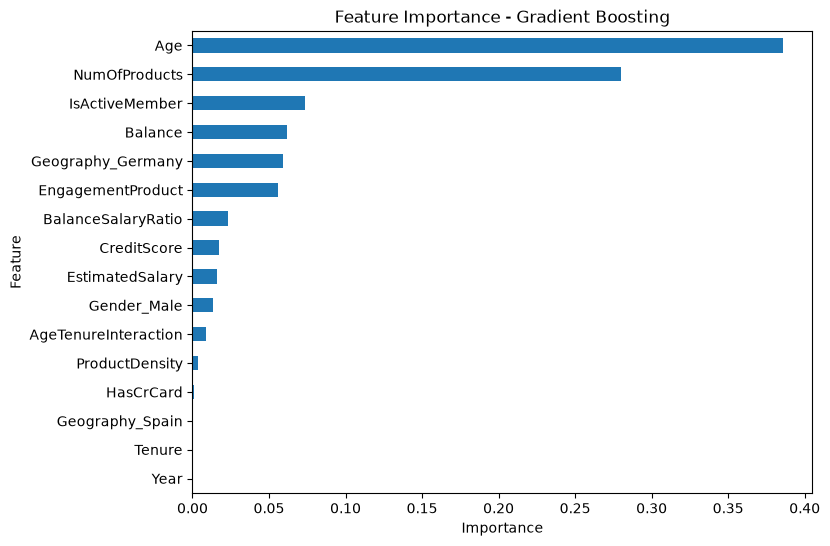

In [140]:
plt.figure(figsize=(8, 6))

feature_importance.sort_values().plot(kind='barh')

plt.title('Feature Importance - Gradient Boosting')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

In [147]:
import shap

In [148]:
explainer = shap.TreeExplainer(final_model)

In [149]:
shap_values = explainer.shap_values(X_test)

In [150]:
type(shap_values), np.shape(shap_values)

(numpy.ndarray, (2000, 16))

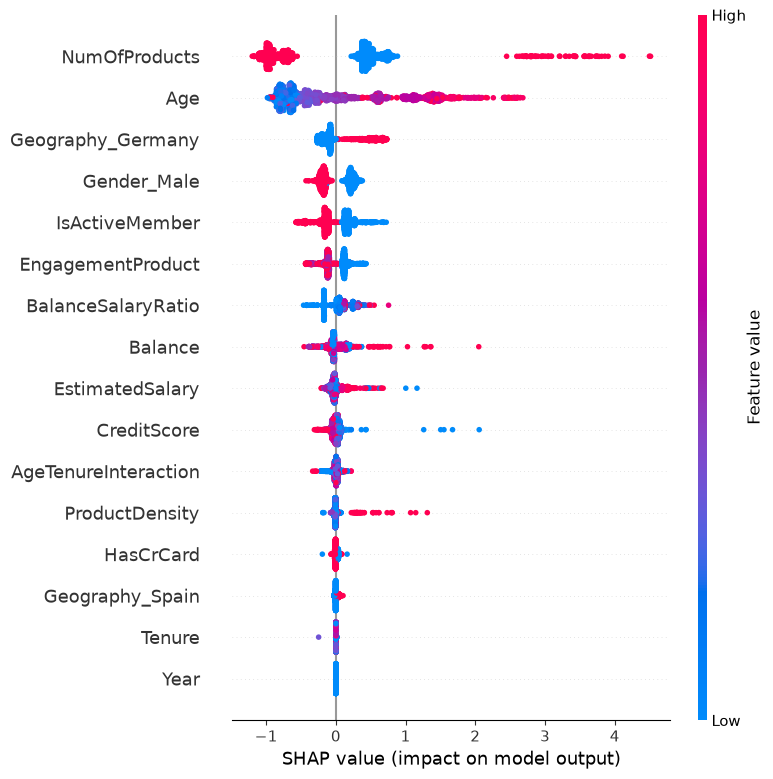

In [151]:
shap.summary_plot(
    shap_values,
    X_test
)

In [152]:
from sklearn.inspection import PartialDependenceDisplay

In [154]:
X_test_pdp = X_test.astype(float)

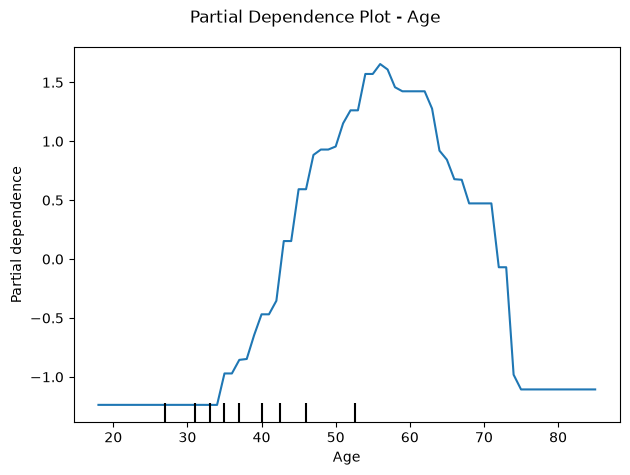

In [155]:
PartialDependenceDisplay.from_estimator(
    final_model,
    X_test_pdp,
    ["Age"]
)

plt.suptitle("Partial Dependence Plot - Age")
plt.tight_layout()
plt.show()

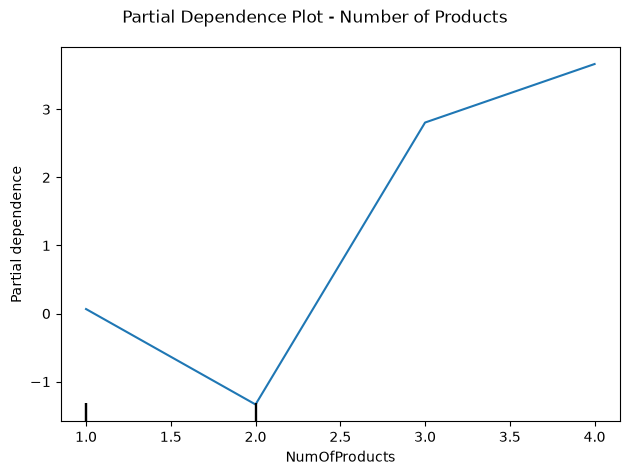

In [156]:
PartialDependenceDisplay.from_estimator(
    final_model,
    X_test_pdp,
    ["NumOfProducts"]
)

plt.suptitle("Partial Dependence Plot - Number of Products")
plt.tight_layout()
plt.show()

In [157]:
final_prob = final_model.predict_proba(X_test)[:, 1]

In [158]:
final_flag = (final_prob >= 0.50).astype(int)

In [159]:
risk_level = pd.cut(
    final_prob,
    bins=[0, 0.30, 0.60, 0.80, 1.00],
    labels=["Low", "Medium", "High", "Very High"],
    include_lowest=True
)

In [160]:
risk_level.value_counts().sort_index()

Low          1578
Medium        231
High           87
Very High     104
Name: count, dtype: int64

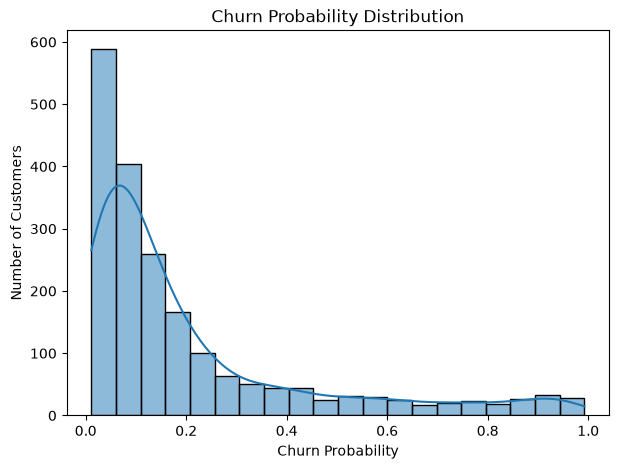

In [161]:
plt.figure(figsize=(7, 5))

sns.histplot(final_prob, bins=20, kde=True)

plt.title("Churn Probability Distribution")
plt.xlabel("Churn Probability")
plt.ylabel("Number of Customers")

plt.show()

<Axes: ylabel='Count'>

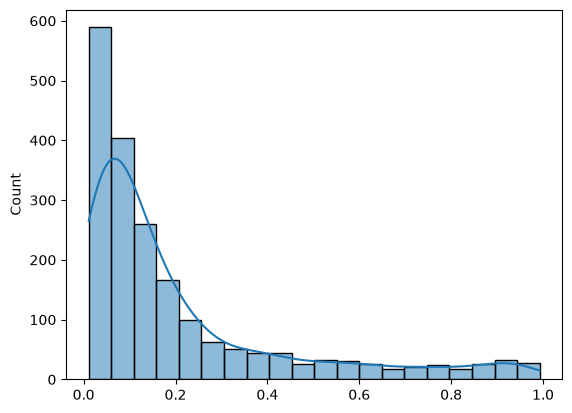

In [162]:
sns.histplot(final_prob, bins=20, kde=True)

In [163]:
import joblib

In [164]:
joblib.dump(final_model, "bank_churn_model.pkl")

['bank_churn_model.pkl']